# 06. Final pipeline

**Question.** Which data, model and inference choices generalise to the test clips, and what is the final solution?

The required detector notebooks (02-05) share one protocol: fold 0, scored windows downscaled to the test sizes. This notebook first checks that protocol against the public leaderboard and fixes it, then separates data (augmentation), model (family, size, schedule) and inference changes (views, tracking, slices, split screens, ensembling). Every late experiment changes one thing against a baseline and is scored on all five folds, next to a repeat of the baseline with another seed as the noise yardstick.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.environ.setdefault("VISDET_DATA", "../../hw2/data")
RUNS = Path(os.environ.get("VISDET_RUNS", "../../hw2/runs"))
from visdet.data.folds import load_folds
from visdet.data.index import load_tables
from visdet.eval.coco import evaluate
from visdet.infer import fusion, tracking
from visdet.viz import style

style.apply()
tables = load_tables()
folds = load_folds(tables)
fold_ids = {k: folds.loc[folds["scored"] & (folds["fold"] == k), "image_id"] for k in range(5)}


def fold_map(run: str, file: str, k: int = 0) -> float:
    pred = pd.read_parquet(RUNS / run / f"fold{k}" / f"{file}.parquet")
    return evaluate(pred, tables, fold_ids[k])["mAP"]

## 1. Does local validation predict the leaderboard?
The first submissions did not keep the local order: test-time augmentation that gained on clean validation frames lost 0.02-0.04 on the leaderboard. Notebook 01 shows why: test frames are 2.4-3.6x blurrier than labelled frames of the same size. The degraded validation (`evalb`: the same scored windows with blur and JPEG fitted to the test sharpness) restores the order. "Greedy temporal" is the first temporal rescoring (per-class IoU linking), later replaced by BoT-SORT (section 4).

In [2]:
lb = pd.read_csv("leaderboard.csv")
evalb = {
    "yolo11s fold0": fold_map("yolo11s", "valb_predictions_1280"),
    "rtdetr-l fold0": fold_map("rtdetr-l", "valb_predictions_1280"),
    "rtdetr-x fold0 plain": fold_map("final-rtdetr-x", "valb_predictions_1280"),
}
views = {
    v: pd.read_parquet(RUNS / "final-rtdetr-x" / "fold0" / f"valb_predictions_{v}.parquet")
    for v in ["1280", "1536", "1792", "flip1536"]
}
tta = fusion.fuse(list(views.values()), tables)
evalb["rtdetr-x fold0 + 4-view TTA (no temporal)"] = evaluate(tta, tables, fold_ids[0])["mAP"]
lb["validation_fold0_evalb"] = lb["submission"].map(evalb)
lb.head(5).set_index("submission")[["validation_fold0_eval", "validation_fold0_evalb", "public_lb"]]

,validation_fold0_eval,validation_fold0_evalb,public_lb
submission,,,
yolo11s fold0,0.2322,0.204707,0.17710
rtdetr-l fold0,0.3047,0.273229,0.33202
rtdetr-x fold0 + 4-view TTA + greedy temporal,0.3299,NaN,0.28036
rtdetr-x fold0 plain,0.3082,0.269991,0.29925
rtdetr-x fold0 + greedy temporal,0.3230,NaN,0.31881


In [3]:
pd.Series(evalb, name="fold-0 evalb mAP").round(3)

yolo11s fold0                                0.205
rtdetr-l fold0                               0.273
rtdetr-x fold0 plain                         0.270
rtdetr-x fold0 + 4-view TTA (no temporal)    0.268
Name: fold-0 evalb mAP, dtype: float64

## 2. Tuned model of each family on both validation sets (fold 0)

In [4]:
rows = {}
for run, evalb_file in [
    ("faster-rcnn-proposals", "evalb_predictions_1280"),
    ("retinanet-focal", "evalb_predictions_1280"),
    ("yolo11s-downscale", "evalb_predictions_1280"),
    ("yolo11m", "evalb_predictions_1280"),
    ("rtdetr-l", "valb_predictions_1280"),
    ("final-rtdetr-x", "valb_predictions_1280"),
]:
    rows[run] = {"eval": fold_map(run, "val_predictions"), "evalb": fold_map(run, evalb_file)}
rows["dfine-x-aug (D-FINE-X, 12 ep)"] = {
    "eval": np.nan,
    "evalb": fold_map("dfine-x-aug-e11", "val_predictions"),
}
pd.DataFrame(rows).T.round(3)

,eval,evalb
faster-rcnn-proposals,0.249,0.234
retinanet-focal,0.222,0.205
yolo11s-downscale,0.245,0.232
yolo11m,0.260,0.233
rtdetr-l,0.305,0.273
final-rtdetr-x,0.308,0.270
"dfine-x-aug (D-FINE-X, 12 ep)",NaN,0.297


## 3. Data strategy: augmentations that imitate the test frames (fold 0, evalb)
`downscale`: shrink and enlarge back (p 0.5, scale 0.35-1); `degrade`: Gaussian blur sigma 0.3-1.0 and JPEG quality 40-90 (p 0.5). Same model and schedule within each block, so the difference is the data alone. D-FINE-X is trained with downscale and motion blur (Albumentations) from here on.

In [5]:
data = {
    "RT-DETR-l": {
        "none": fold_map("rtdetr-l", "valb_predictions_1280"),
        "downscale": fold_map("rtdetr-l-downscale", "evalb_predictions_1280"),
        "degrade": fold_map("rtdetr-l-degrade", "val_predictions"),
        "both": fold_map("rtdetr-l-degrade-downscale", "val_predictions"),
    },
    "YOLO11m": {
        "none": fold_map("yolo11m", "evalb_predictions_1280"),
        "downscale": fold_map("yolo11m-downscale-repeat", "evalb_predictions_1280"),
        "degrade": fold_map("yolo11m-degrade", "val_predictions"),
        "both": fold_map("yolo11m-degrade-downscale", "val_predictions"),
    },
}
pd.DataFrame(data).T.round(3)

,none,downscale,degrade,both
RT-DETR-l,0.273,0.282,0.278,0.277
YOLO11m,0.233,0.237,0.241,0.239


## 4. Inference: TTA views and BoT-SORT track rescoring (RT-DETR-x, fold 0, evalb)
Views are the inference size (long side) and a horizontal flip. Tracking (`visdet.infer.tracking`): Ultralytics BoT-SORT with camera-motion compensation links the detections of each PySceneDetect segment; each linked score is blended with the top scores of its class in the track (alpha 0.25).

In [6]:
res = {f"view {v}": evaluate(p, tables, fold_ids[0])["mAP"] for v, p in views.items()}
res["4-view TTA"] = evalb["rtdetr-x fold0 + 4-view TTA (no temporal)"]
res["1280 + BoT-SORT rescoring"] = evaluate(
    tracking.rescore(views["1280"], tables.frames), tables, fold_ids[0]
)["mAP"]
pd.Series(res, name="mAP").round(3)

view 1280                    0.270
view 1536                    0.265
view 1792                    0.253
view flip1536                0.256
4-view TTA                   0.268
1280 + BoT-SORT rescoring    0.282
Name: mAP, dtype: float64

## 5. D-FINE-X and the late one-change experiments (5 folds, evalb)
D-FINE-X (Objects365 -> COCO weights) became the strongest single model. All runs below are D-FINE-X, 1280 px, downscale and motion blur, 20 epochs, epoch 19 EMA weights; each differs from `aug20` in one thing:
- `aug20 seed 1`: nothing but the seed (noise yardstick);
- `slice`: slicing-aided fine-tuning (SAHI paper): half of the samples are a random 640x640 crop of the frame;
- `mosaic`: 4-frame mosaic with p 0.5 (D-FINE's Mosaic, fixed to use the sampled frame as a tile);
- `kornia DIP`: a learned enhancement module in front of the backbone (IA-YOLO style, `visdet.models.enhance`).

In [7]:
exps = {
    "aug (12 ep)": "dfine-x-aug-e11",
    "aug20": "dfine-x-aug20-e19",
    "aug20 seed 1": "dfine-x-aug20s1-e19",
    "slice": "dfine-x-slice-e19",
    "mosaic": "dfine-x-mosaic-e19",
    "kornia DIP": "dfine-x-dip-e19",
}
per_fold = pd.DataFrame(
    {name: [fold_map(run, "val_predictions", k) for k in range(5)] for name, run in exps.items()}
)
per_fold.loc["mean"] = per_fold.mean()
base = per_fold.loc[range(5), ["aug20", "aug20 seed 1"]].mean(axis=1)
per_fold.loc["mean - baseline pair"] = per_fold.loc[range(5)].sub(base, axis=0).mean()
per_fold.round(4)

,aug (12 ep),aug20,aug20 seed 1,slice,mosaic,kornia DIP
0,0.2970,0.3463,0.3411,0.3387,0.3385,0.3315
1,0.3565,0.3476,0.3511,0.3571,0.3625,0.3202
2,0.2878,0.2955,0.2825,0.2873,0.2908,0.2887
3,0.3759,0.3372,0.3675,0.3731,0.3701,0.3694
4,0.2106,0.2657,0.2595,0.2596,0.2599,0.2660
mean,0.3055,0.3185,0.3203,0.3232,0.3244,0.3152
mean - baseline pair,-0.0139,-0.0009,0.0009,0.0038,0.0050,-0.0043


The seed repeat alone moves single folds by up to 0.03, so a mean change below ~0.005 is not separable from noise. Slice training and mosaic are inside it; the learned enhancement is slightly negative.

**SAHI inference** (full frame + 640 px slices with 25% overlap, class-wise NMS 0.5, `visdet.infer.crops`) for the normal and the slice-trained model:

In [8]:
sahi = pd.DataFrame(
    {
        model: {
            "full frame": np.mean([fold_map(run, "val_predictions_full", k) for k in range(5)]),
            "full + slices (SAHI)": np.mean(
                [fold_map(run, "val_predictions", k) for k in range(5)]
            ),
        }
        for model, run in [
            ("normal training", "dfine-x-aug20-e19-sahi"),
            ("slice training", "dfine-x-slice-e19-sahi"),
        ]
    }
).T
sahi.round(4)

,full frame,full + slices (SAHI)
normal training,0.3185,0.3256
slice training,0.3232,0.3209


## 6. What the learned enhancement does
The module predicts per-image white-balance gains, gamma, contrast and two sharpening amounts from a 256 px thumbnail; it starts as the identity and is trained by the detection loss only. Parameters on every 10th test frame (fold-0 model):

In [9]:
import torch
import torchvision.transforms.functional as F
from PIL import Image

from visdet.models.enhance import PARAMS, KorniaDIP

dip = KorniaDIP()
dip.load_state_dict(torch.load(RUNS / "dfine-x-dip-enhance" / "fold0.pt"))
dip.eval()
test = tables.frames[tables.frames["split"] == "test"].sort_values("image_id")


def model_input(file: str) -> torch.Tensor:  # stretched to the 1280 square, as in training
    return F.to_tensor(
        F.resize(Image.open(Path(os.environ["VISDET_DATA"]) / file).convert("RGB"), [1280, 1280])
    )[None]


params = []
with torch.no_grad():
    for r in test.iloc[::10].itertuples():
        p = dip.params(model_input(r.file))
        params.append({"clip": r.clip} | {n: float(p[n]) for n in PARAMS})
params = pd.DataFrame(params)
by_clip = params.groupby("clip").mean()
pd.concat(
    [
        params[list(PARAMS)].describe().loc[["mean", "min", "max"]],
        by_clip.sort_values("gamma").head(3),
    ]
).round(3)

,wb_r,wb_g,wb_b,gamma,contrast,sharpness,unsharp
mean,0.998,0.992,1.010,0.978,1.004,1.023,0.066
min,0.994,0.991,1.010,0.889,1.003,0.985,0.047
max,0.999,0.993,1.012,0.990,1.007,1.302,0.218
clip_020,0.994,0.991,1.012,0.890,1.007,1.298,0.216
clip_030,0.997,0.992,1.010,0.941,1.005,1.131,0.127
clip_035,0.997,0.992,1.010,0.947,1.005,1.115,0.117


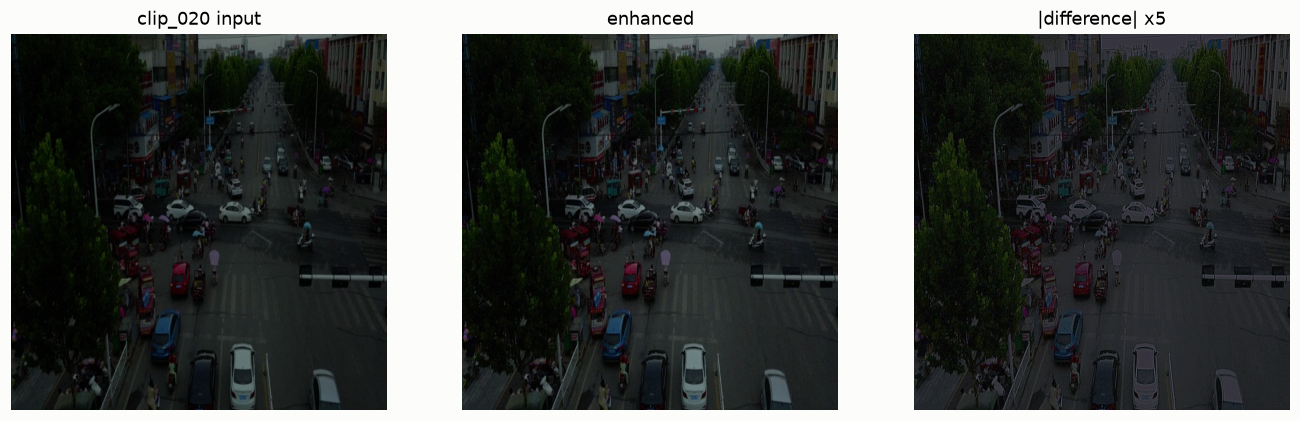

In [10]:
with torch.no_grad():
    x = model_input(test.loc[test["image_id"] == "clip_020_0000040", "file"].item())
    y = dip(x)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, title in zip(
    ax, [x, y, (y - x).abs() * 5], ["clip_020 input", "enhanced", "|difference| x5"], strict=True
):
    a.imshow(im[0].permute(1, 2, 0).clamp(0, 1).numpy())
    a.set_title(title)
    a.axis("off")

The module stays near the identity on normal frames and brightens and sharpens the darkest test clips (clip_020, clip_030); all five fold models learned the same direction. Validation has almost no dark frames, so mAP cannot show a benefit; the published methods train on synthetic fog or low light for this reason (IA-YOLO, GDIP).

## 7. Final ensemble, out of fold and on the leaderboard
Members: RT-DETR-l + downscale (two seeds), RT-DETR-x + downscale (two seeds), RT-DETR-x, YOLO11m + blur/JPEG, YOLO11m + downscale, and D-FINE-X (5 fold models, weight 2). Test: split-screen segments (`visdet.infer.layout`) are predicted per panel; each model's fold predictions are de-duplicated by NMS, then all members are fused by WBF; BoT-SORT rescoring runs per segment and panel. Out of fold covers all 63 clips once (evalb).

In [11]:
rows = lb[lb["ensemble"].notna()].set_index("submission")[["ensemble", "public_lb"]]
rows["oof_mAP"] = [
    json.loads((RUNS / "ensembles" / e / "metrics.json").read_text())["mAP"]
    for e in rows["ensemble"]
]
rows[["oof_mAP", "public_lb"]].round(4)

,oof_mAP,public_lb
submission,,
"final-a (7 members, WBF, greedy temporal)",0.3025,0.3648
final-a members + BoT-SORT,0.2995,0.3660
+ D-FINE-X 5 folds (weight 2),0.3134,0.3748
"+ per-model NMS, per-panel split screens",0.3176,0.3820
D-FINE 20 epochs instead of 12,0.3206,0.3822
D-FINE alone (no other members),0.2869,0.3770
+ SAHI inference for D-FINE,0.3229,0.3826
+ Kornia DIP D-FINE instead of plain (no SAHI),0.3199,0.3814


Note: `final-a` used the first, greedy temporal linking; every later row uses BoT-SORT.

## Conclusions
- Local validation must reproduce the test frames: on clean frames multi-scale TTA looked best and lost on the leaderboard; frames degraded to the test sharpness reproduce the leaderboard order.
- Data changes that imitate the test frames help on that validation (downscale for RT-DETR, blur/JPEG for YOLO11m).
- D-FINE-X is the strongest single model; on the leaderboard it alone reaches 0.377, and the RT-DETR/YOLO members add 0.005.
- On the leaderboard, adding D-FINE-X to final-a gave +0.009, per-panel detection on split screens with NMS before WBF +0.007, BoT-SORT instead of greedy linking +0.001; 20 instead of 12 epochs changed nothing.
- One-change experiments at the end: SAHI inference helps a little (+0.007 single model, +0.002 ensemble OOF, +0.0003 leaderboard); slice training, mosaic and the learned enhancement stay within seed noise.